# Etapa 6 - Lógica fuzzy (Membro 6)
Domínio P4 - Meio Ambiente (autos de infração do IBAMA, 2021).

Antes de executar: o notebook procura tabela_p4.csv e probs_rede.csv na pasta atual, em dados/ e em ../dados/. Se não achar, ele baixa os dois da pasta dados/ do repositório do grupo no GitHub. Se o download falhar, baixe os arquivos à mão e coloque na mesma pasta do notebook.

- tabela_p4.csv (feito na Etapa 1)
- probs_rede.csv (feito na Etapa 5)

Depois é só rodar as células de cima para baixo. Se rodar de novo só a célula do item 2, rode também as dos itens 3 e 5, porque ela recria o fuzzy.py.

O notebook cria o arquivo fuzzy.py e as figuras da pasta figuras/.

In [2]:
%pip install numpy pandas matplotlib scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 11.1 MB/s  0:00:00


In [3]:
import os
import urllib.request

URL_BASE = "https://raw.githubusercontent.com/rafaellydosanjos/2o-Trab-SimbML-Incerteza_equipe_3/main/dados/"

def obter(nome):
    """Usa o arquivo local se existir. Se não, baixa do GitHub."""
    for pasta in ['.', 'dados', '../dados']:
        caminho = os.path.join(pasta, nome)
        if os.path.exists(caminho):
            return caminho
    try:
        os.makedirs('dados', exist_ok=True)
        caminho = os.path.join('dados', nome)
        urllib.request.urlretrieve(URL_BASE + nome, caminho)
        print('Baixado do GitHub:', nome)
        return caminho
    except Exception as erro:
        print('Não consegui baixar', nome, '->', erro)
        return None

CAMINHO_TABELA = obter('tabela_p4.csv')
CAMINHO_PROBS = obter('probs_rede.csv')

print('tabela_p4.csv  ->', CAMINHO_TABELA)
print('probs_rede.csv ->', CAMINHO_PROBS)

if CAMINHO_TABELA is None:
    raise FileNotFoundError("Falta o arquivo tabela_p4.csv. Veja 'Antes de executar' no início do notebook.")
if CAMINHO_PROBS is None:
    print("AVISO: probs_rede.csv não encontrado. O item 4 precisa desse arquivo.")

tabela_p4.csv  -> dados/tabela_p4.csv
probs_rede.csv -> dados/probs_rede.csv


1. Variáveis linguísticas: escala da variável efeito:

In [4]:
import os
import numpy as np
import pandas as pd

np.random.seed(42)

tabela = pd.read_csv(CAMINHO_TABELA, encoding='utf-8-sig')

escala = {'Desprezível': 0, 'Fraca': 1, 'Moderada': 2, 'Significativa': 3}
efeito_num = tabela['EFEITO_MEIO_AMBIENTE'].map(escala)
print(efeito_num.value_counts(dropna=False).sort_index())

EFEITO_MEIO_AMBIENTE
0.0     81
1.0    657
2.0    528
3.0    613
NaN    760
Name: count, dtype: int64


2. Funções de pertinência e regras Se-Então (sistema Mamdani):

In [5]:
%%writefile fuzzy.py
"""
Sistema Mamdani com 2 entradas e 1 saída:
  risco      (0 a 1)   probabilidade de multa alta (virá da Rede Bayesiana, Etapa 5)
  efeito     (0 a 3)   efeito da infração no meio ambiente (0 = Desprezível ... 3 = Significativa)
  prioridade (0 a 100) saída do sistema
"""
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

np.random.seed(42)


def criar_sistema_fuzzy():
    """Cria e devolve (sistema, risco, efeito, prioridade)."""
    # Variáveis linguísticas
    risco = ctrl.Antecedent(np.arange(0, 1.001, 0.01), 'risco')
    efeito = ctrl.Antecedent(np.arange(0, 3.001, 0.05), 'efeito')
    prioridade = ctrl.Consequent(np.arange(0, 100.1, 1), 'prioridade')

    # trimf(universo, [a, b, c]): sobe de a até b (pico = 1) e desce até c
    # triângulos de risco ajustados à distribuição das probabilidades da rede
    # (elas ficam perto de 0,1 a 0,2, de 0,4 e de 0,65 a 0,7)
    risco['baixo'] = fuzz.trimf(risco.universe, [0.0, 0.0, 0.4])
    risco['medio'] = fuzz.trimf(risco.universe, [0.2, 0.45, 0.7])
    risco['alto'] = fuzz.trimf(risco.universe, [0.5, 1.0, 1.0])

    efeito['fraco'] = fuzz.trimf(efeito.universe, [0.0, 0.0, 1.5])
    efeito['medio'] = fuzz.trimf(efeito.universe, [0.5, 1.5, 2.5])
    efeito['forte'] = fuzz.trimf(efeito.universe, [1.5, 3.0, 3.0])

    prioridade['baixa'] = fuzz.trimf(prioridade.universe, [0, 0, 50])
    prioridade['media'] = fuzz.trimf(prioridade.universe, [25, 50, 75])
    prioridade['alta'] = fuzz.trimf(prioridade.universe, [50, 100, 100])

    # Regras Se-Então: & = E (mínimo), | = OU (máximo)
    r1 = ctrl.Rule(risco['alto'] & (efeito['medio'] | efeito['forte']), prioridade['alta'])
    r2 = ctrl.Rule(risco['alto'] & efeito['fraco'], prioridade['media'])
    r3 = ctrl.Rule(risco['medio'], prioridade['media'])
    r4 = ctrl.Rule(risco['baixo'] & efeito['forte'], prioridade['media'])
    r5 = ctrl.Rule(risco['baixo'] & (efeito['fraco'] | efeito['medio']), prioridade['baixa'])

    sistema = ctrl.ControlSystem([r1, r2, r3, r4, r5])
    return sistema, risco, efeito, prioridade

Writing fuzzy.py


In [6]:
import importlib, fuzzy
importlib.reload(fuzzy)

sistema, risco_v, efeito_v, prioridade_v = fuzzy.criar_sistema_fuzzy()
print(list(risco_v.terms), list(efeito_v.terms), list(prioridade_v.terms))
print(len(list(sistema.rules)), 'regras')

['baixo', 'medio', 'alto'] ['fraco', 'medio', 'forte'] ['baixa', 'media', 'alta']
5 regras


3. Inferência e testes do sistema:

In [7]:
%%writefile -a fuzzy.py


def inferir(sistema, risco_val, efeito_val):
    """Roda o sistema para UM par de entradas e devolve a prioridade (0-100)."""
    sim = ctrl.ControlSystemSimulation(sistema)
    sim.input['risco'] = float(np.clip(risco_val, 0, 1))
    sim.input['efeito'] = float(np.clip(efeito_val, 0, 3))
    sim.compute()
    return float(sim.output['prioridade'])


def decisao_dura(p, limiar=0.5):
    """Decisão rígida: acima do limiar = ALTA, senão BAIXA."""
    return 'ALTA' if p >= limiar else 'BAIXA'


def rotulo_fuzzy(prioridade):
    """Traduz o número da saída em palavra, só para facilitar a leitura."""
    if prioridade < 33:
        return 'baixa'
    if prioridade < 66:
        return 'media'
    return 'alta'

Appending to fuzzy.py


In [8]:
importlib.reload(fuzzy)
sistema, risco_v, efeito_v, prioridade_v = fuzzy.criar_sistema_fuzzy()

for p, e in [(0.10, 0), (0.45, 1), (0.55, 2), (0.80, 3), (0.95, 3)]:
    pri = fuzzy.inferir(sistema, p, e)
    print(f'risco={p:.2f} efeito={e} -> prioridade={pri:.1f} | dura: {fuzzy.decisao_dura(p)}')

risco=0.10 efeito=0 -> prioridade=17.5 | dura: BAIXA
risco=0.45 efeito=1 -> prioridade=50.0 | dura: BAIXA
risco=0.55 efeito=2 -> prioridade=54.1 | dura: ALTA
risco=0.80 efeito=3 -> prioridade=81.4 | dura: ALTA
risco=0.95 efeito=3 -> prioridade=83.2 | dura: ALTA


4. Comparação fuzzy x decisão rígida:

Usamos as probabilidades da rede (Etapa 5) como o risco do sistema fuzzy e comparamos com a decisão rígida (risco de 0,5 em diante = multa alta). Entram só os autos que têm efeito, então os 760 sem efeito ficam de fora.

4.1 Juntar a tabela com as probabilidades da rede:

In [9]:
tabela = pd.read_csv(CAMINHO_TABELA, encoding='utf-8-sig')
probs = pd.read_csv(CAMINHO_PROBS)

assert len(tabela) == len(probs) == 2639, (len(tabela), len(probs))
assert probs['p_multa_alta'].notna().all()
assert probs['p_multa_alta'].between(0, 1).all()

tabela['risco'] = probs['p_multa_alta'].values
tabela['efeito'] = tabela['EFEITO_MEIO_AMBIENTE'].map(escala)

print(tabela['risco'].describe().round(3))
print('valores distintos de risco:', tabela['risco'].nunique())
print(pd.cut(tabela['risco'], [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True).value_counts().sort_index())

count    2639.000
mean        0.499
std         0.238
min         0.028
25%         0.199
50%         0.642
75%         0.693
max         0.947
Name: risco, dtype: float64
valores distintos de risco: 26
risco
(-0.001, 0.2]     706
(0.2, 0.4]        126
(0.4, 0.6]        201
(0.6, 0.8]       1600
(0.8, 1.0]          6
Name: count, dtype: int64


4.2 Rodar o fuzzy nos autos que têm efeito:

In [10]:
importlib.reload(fuzzy)
sistema, risco_v, efeito_v, prioridade_v = fuzzy.criar_sistema_fuzzy()

base = tabela.dropna(subset=['efeito']).copy()
print('Autos com efeito:', len(base), 'de', len(tabela))

pares = base[['risco', 'efeito']].drop_duplicates()
cache = {(r, e): fuzzy.inferir(sistema, r, e) for r, e in zip(pares['risco'], pares['efeito'])}

base['prioridade'] = [cache[(r, e)] for r, e in zip(base['risco'], base['efeito'])]
base['decisao_dura'] = base['risco'].apply(fuzzy.decisao_dura)
base['rotulo_fuzzy'] = base['prioridade'].apply(fuzzy.rotulo_fuzzy)

Autos com efeito: 1879 de 2639


4.3 Comparar a decisão rígida com o rótulo do fuzzy:

A coluna "media" mostra os autos que o fuzzy deixa no meio.

In [11]:
print(pd.crosstab(base['decisao_dura'], base['rotulo_fuzzy']))
print(base.groupby('Multa_Alta')['prioridade'].mean().round(1))

rotulo_fuzzy  alta  baixa  media
decisao_dura                    
ALTA           539      0    611
BAIXA            0    462    267
Multa_Alta
0    44.5
1    66.6
Name: prioridade, dtype: float64


4.4 Ver os autos com risco perto de 0,5 (entre 0,4 e 0,6):

In [12]:
fronteira = base[base['risco'].between(0.4, 0.6)]
print(len(fronteira), 'autos com risco entre 0,4 e 0,6')
print(fronteira.groupby('efeito')['prioridade'].describe().round(1))

132 autos com risco entre 0,4 e 0,6
        count  mean  std   min   25%   50%   75%   max
efeito                                                
0.0       2.0  50.0  0.0  50.0  50.0  50.0  50.0  50.0
1.0      75.0  50.0  0.0  50.0  50.0  50.0  50.0  50.0
2.0      22.0  50.4  1.5  50.0  50.0  50.0  50.0  57.1
3.0      33.0  50.2  1.2  50.0  50.0  50.0  50.0  57.1


5. Gráficos: pertinências e superfície de resposta:

In [13]:
%%writefile -a fuzzy.py


def plot_pertinencias(variaveis, salvar_em=None):
    """Desenha as funções de pertinência de cada variável."""
    fig, eixos = plt.subplots(1, len(variaveis), figsize=(5 * len(variaveis), 3.5))
    for ax, var in zip(np.atleast_1d(eixos), variaveis):
        for nome, termo in var.terms.items():
            ax.plot(var.universe, termo.mf, label=nome, linewidth=2)
        ax.set_title(var.label)
        ax.set_xlabel(var.label)
        ax.set_ylabel('pertinencia')
        ax.legend()
    plt.tight_layout()
    if salvar_em:
        plt.savefig(salvar_em, dpi=150)
    plt.show()


def plot_superficie(sistema, passos=15, salvar_em=None):
    """Superfície 3D: prioridade em função de (risco, efeito)."""
    sim = ctrl.ControlSystemSimulation(sistema)
    rs = np.linspace(0, 1, passos)
    es = np.linspace(0, 3, passos)
    Z = np.zeros((passos, passos))
    for i, e in enumerate(es):
        for j, r in enumerate(rs):
            sim.input['risco'] = r
            sim.input['efeito'] = e
            sim.compute()
            Z[i, j] = sim.output['prioridade']
    R, E = np.meshgrid(rs, es)
    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(R, E, Z, cmap='viridis')
    ax.set_xlabel('risco')
    ax.set_ylabel('efeito')
    ax.set_zlabel('prioridade')
    plt.tight_layout()
    if salvar_em:
        plt.savefig(salvar_em, dpi=150)
    plt.show()

Appending to fuzzy.py


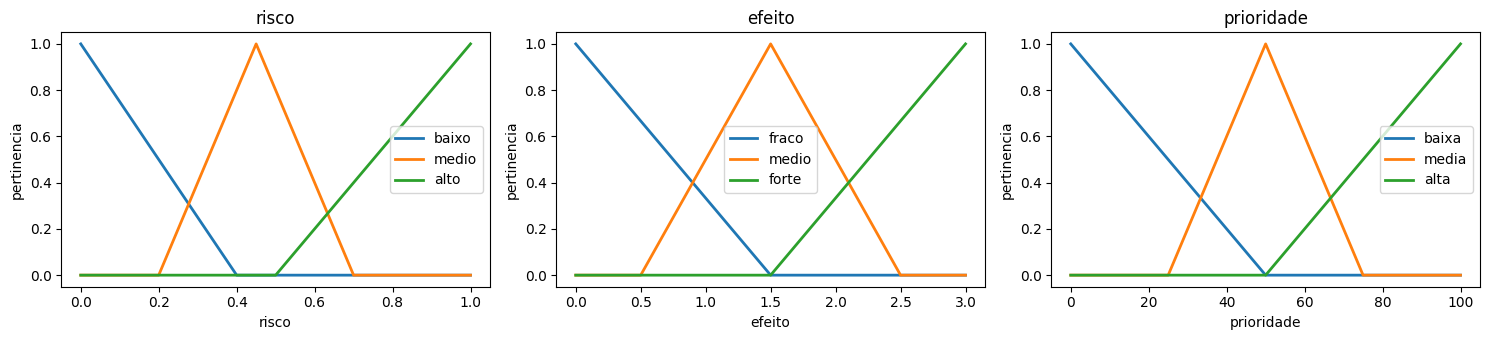

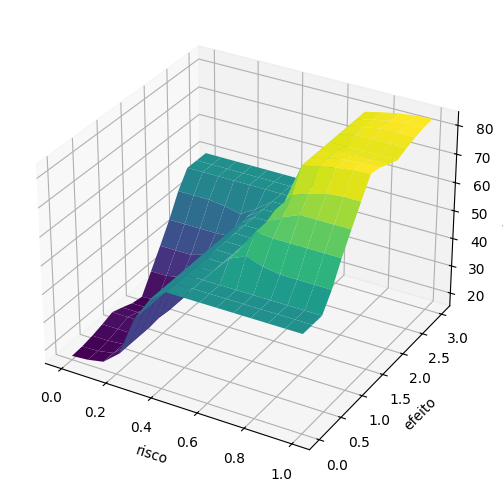

In [14]:
importlib.reload(fuzzy)
sistema, risco_v, efeito_v, prioridade_v = fuzzy.criar_sistema_fuzzy()
os.makedirs('figuras', exist_ok=True)

fuzzy.plot_pertinencias([risco_v, efeito_v, prioridade_v], salvar_em='figuras/pertinencias.png')
fuzzy.plot_superficie(sistema, salvar_em='figuras/superficie.png')